In [2]:
import pyvista as pv
import glob
import os
import numpy as np

In [3]:
model_name = 'simulation_sediment_on_top_1.5m'
source_type = 'wh'
# get folders from the model output directory
output_folders = glob.glob(f'/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/{model_name}/RESULTS/*')

# select folder name that ends witn _wh
output_folder = [folder for folder in output_folders if folder.endswith(f'_{source_type}')][0]

# 1. Read the VTK dataset
mesh = pv.read(f"{output_folder}/mesh_materials.vtk")

# 2. Check available data arrays (scalars or vectors) inside your file
print("Available data arrays:", mesh.array_names)

# remap the scalar or vector data if needed
# Example: mesh['remapped_data'] = mesh['original_data'] * 2

Available data arrays: ['elem_flag']


In [4]:
material_id = mesh.cell_data['elem_flag']

np.unique(material_id)[0]

np.int32(1)

In [5]:
# read receiver coordinates
stations = np.genfromtxt(f'/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/{model_name}/DATA/STATIONS')

coord_x = stations[:,2]
coord_y = stations[:,4]
coord_z = stations[:,3]

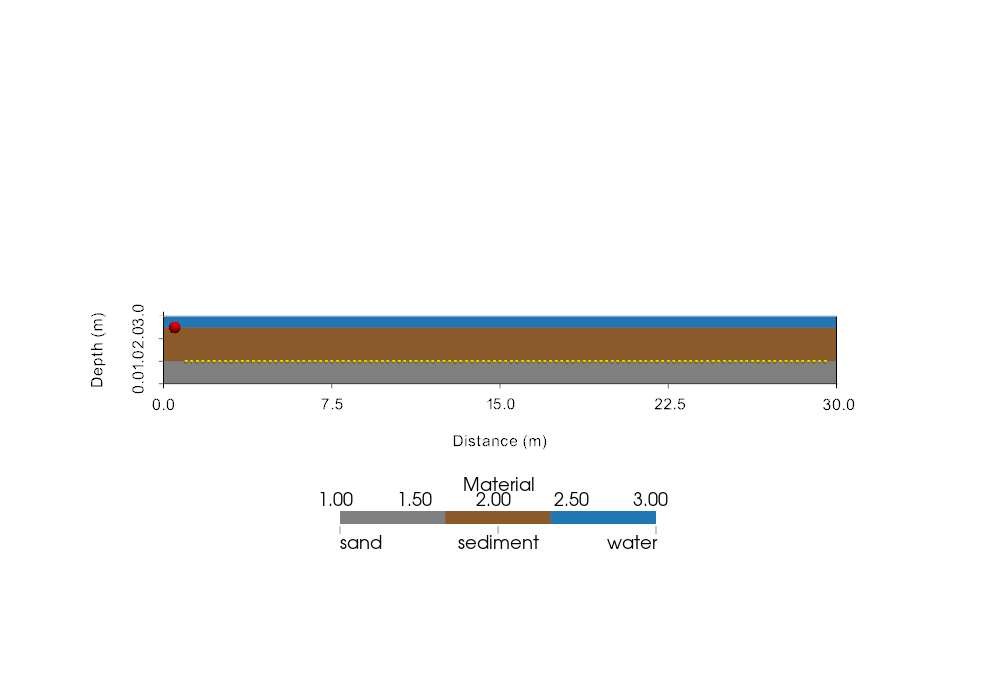

In [8]:
# Plot only the mesh section with x in [0, 30] m and z in [0, 3] m
pv.set_jupyter_backend("static")
from matplotlib import colormaps, colors as mcolors

xmin, xmax, ymin, ymax, zmin, zmax = mesh.bounds
x0, x1 = 0.0, 30.0
z0, z1 = 0, 3.0

mesh_section = mesh.clip_box(
    bounds=(x0, x1, ymin, ymax, z0, z1),
    invert=False,
    crinkle=True,
    merge_points=False,
)

# Build a discrete colormap with one selectable color per material
raw_material = mesh_section.cell_data["elem_flag"]
unique_materials = np.unique(raw_material)
n_materials = len(unique_materials)

# User-selectable colors by material ID (edit these as needed)
material_color_map = {
    1: "#808080",  # gray
    2: "#8B5A2B",  # brown
    3: "#1F77B4",  # blue (water)
}

# User-selectable names for displayed material classes (1..N)
material_name_map = {
    1: "sand",
    2: "sediment",
    3: "water",
}

# Fallback palette for any material IDs not explicitly listed
fallback = colormaps["tab20"].resampled(max(n_materials, 1))(np.arange(max(n_materials, 1)))

# Map materials to 1..N
material_idx = np.zeros(raw_material.shape, dtype=np.int32)
for idx, mat in enumerate(unique_materials):
    material_idx[raw_material == mat] = idx + 1

mesh_section = mesh_section.copy()
mesh_section.cell_data["material_idx"] = material_idx

material_colors = []
for idx, mat in enumerate(unique_materials):
    mat_int = int(mat)
    if mat_int in material_color_map:
        material_colors.append(material_color_map[mat_int])
    else:
        material_colors.append(mcolors.to_hex(fallback[idx]))

cmap = mcolors.ListedColormap(material_colors)
annotations = {float(i): material_name_map.get(i, f"material_{i}") for i in range(1, n_materials + 1)}

plotter = pv.Plotter(notebook=True, window_size=(1000, 700))
plotter.add_mesh(
    mesh_section,
    scalars="material_idx",
    cmap=cmap,
    categories=True,
    annotations=annotations,
    clim=[1.0, float(n_materials)],
    show_scalar_bar=True,
    scalar_bar_args={
        "title": "Material",
        "vertical": False,
        "position_x": 0.34,
        "position_y": 0.25,
        "width": 0.32,
        "height": 0.05,
    },
    show_edges=False,
    edge_color="black",
    line_width=0.1,
    lighting=False,
)

if all(name in globals() for name in ["coord_x", "coord_z"]):
    in_range = (coord_x >= x0) & (coord_x <= x1) & (coord_z >= z0) & (coord_z <= z1)
    station_points = np.column_stack((
        coord_x[in_range],
        np.zeros_like(coord_x[in_range]),
        coord_z[in_range],
    ))
    if station_points.size > 0:
        plotter.add_points(
            station_points,
            color="yellow",
            point_size=4,
            render_points_as_spheres=True,
        )


# include source position at (x=0, y=0, z=0)
source_point = np.array([[0.5, 0.0, 2.5]])
plotter.add_points(
    source_point,
    color="red",
    point_size=12,
    render_points_as_spheres=True,
)

# Show built-in vertical ticks/labels on depth axis
plotter.show_bounds(
    bounds=(x0, x1, -1e-6, 1e-6, z0, z1),
    xtitle="Distance (m)",
    ytitle="y (m)",
    ztitle="Depth (m)",
    show_zlabels=True,
    n_zlabels=4,
    location="outer",
    all_edges=True,
    ticks="outside",
    fmt="%.1f",
    font_size=12,
)

plotter.view_xz()


plotter.show()

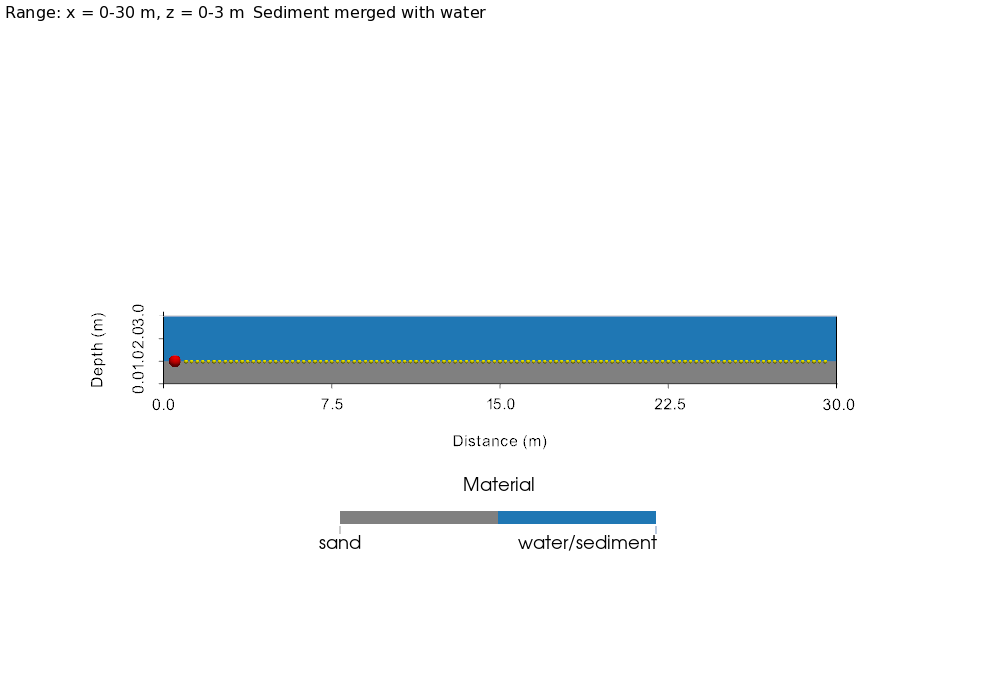

In [7]:
# Second plot: sediment merged into water
pv.set_jupyter_backend("static")
from matplotlib import colors as mcolors

mesh_section_2 = mesh.clip_box(
    bounds=(x0, x1, ymin, ymax, z0, z1),
    invert=False,
    crinkle=True,
    merge_points=False,
)

raw_material_2 = mesh_section_2.cell_data["elem_flag"]
class_map = {1: 1, 2: 2, 3: 2}

material_idx_2 = np.zeros(raw_material_2.shape, dtype=np.int32)
for mat in np.unique(raw_material_2):
    material_idx_2[raw_material_2 == mat] = class_map.get(int(mat), 1)

mesh_section_2 = mesh_section_2.copy()
mesh_section_2.cell_data["material_idx_2"] = material_idx_2

cmap_2 = mcolors.ListedColormap(["#808080", "#1F77B4"])
annotations_2 = {1.0: "sand", 2.0: "water/sediment"}

plotter2 = pv.Plotter(notebook=True, window_size=(1000, 700))
plotter2.add_mesh(
    mesh_section_2,
    scalars="material_idx_2",
    cmap=cmap_2,
    categories=True,
    annotations=annotations_2,
    clim=[1.0, 2.0],
    show_scalar_bar=True,
    scalar_bar_args={
        "title": "Material",
        "vertical": False,
        "position_x": 0.34,
        "position_y": 0.25,
        "width": 0.32,
        "height": 0.05,
    },
    show_edges=False,
    edge_color="black",
    line_width=0.3,
    lighting=False,
)

# Keep annotation labels only (hide numeric tick labels)
scalar_bar_2 = plotter2.scalar_bar
if scalar_bar_2 is not None:
    scalar_bar_2.SetDrawTickLabels(False)
    scalar_bar_2.SetDrawAnnotations(True)

if all(name in globals() for name in ["coord_x", "coord_z"]):
    in_range_2 = (coord_x >= x0) & (coord_x <= x1) & (coord_z >= z0) & (coord_z <= z1)
    station_points_2 = np.column_stack((
        coord_x[in_range_2],
        np.zeros_like(coord_x[in_range_2]),
        coord_z[in_range_2],
    ))
    if station_points_2.size > 0:
        plotter2.add_points(
            station_points_2,
            color="yellow",
            point_size=4,
            render_points_as_spheres=True,
        )

# Add source location at x=0.5 m, z=1.0 m
source_point_2 = np.array([[0.5, 0.0, 1.0]])
plotter2.add_points(
    source_point_2,
    color="red",
    point_size=12,
    render_points_as_spheres=True,
)

plotter2.show_bounds(
    bounds=(x0, x1, -1e-6, 1e-6, z0, z1),
    xtitle="Distance (m)",
    ytitle="y (m)",
    ztitle="Depth (m)",
    show_zlabels=True,
    n_zlabels=4,
    location="outer",
    all_edges=True,
    ticks="outside",
    fmt="%.1f",
    font_size=12,
)

plotter2.view_xz()
plotter2.add_text(
    "Range: x = 0-30 m, z = 0-3 m | Sediment merged with water",
    position="upper_left",
    font_size=11,
    color="black",
)
plotter2.show()